# Section 7 — Sequential e-Holm and factorial e-DAG


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

## Multiple-testing procedures

In [2]:
# Compute adjusted e-Holm e-values.
def e_holm(evals):
  if len(evals) == 0:
    return []

  pairs = sorted(enumerate(evals), key=lambda t: t[1], reverse = True)
  orig_idx = [i for i, _ in pairs]
  e_sorted = [x for _, x in pairs]
  n = len(e_sorted)

  e_adjusted = np.zeros(n)
  e_adjusted[n-1] = e_sorted[n-1]

  k = 1
  E_k = e_sorted[n-k]
  e_adj = float('inf')
  for r in range(1, n):
    i = n - 1 - r
    e = e_sorted[i]
    e_adj = e / (k+1) + E_k * k / (k+1)
    while(e_adj > e_sorted[n - k - 1]):
      E_k = E_k * k / (k+1) + e_sorted[n - k - 1] / (k+1)
      k = k + 1
      e_adj = e / (k+1) + E_k * k / (k+1)
      if k == n:
        break
    e_adjusted[i] = e_adj

  adjusted = np.zeros(n)
  for sorted_pos, i in enumerate(orig_idx):
    adjusted[i] = e_adjusted[sorted_pos]
  return adjusted

In [3]:
# Compute adjusted p-Holm p-values.
def p_holm(pvals):
  if len(pvals) == 0:
    return []

  pairs = sorted(enumerate(pvals), key=lambda t: t[1])
  orig_idx = [i for i, _ in pairs]
  p_sorted = [x for _, x in pairs]
  n = len(p_sorted)

  p_adjusted = np.zeros(n)
  p_adj = p_sorted[0] * n
  p_adjusted[0] = p_adj

  for i in range(1,n):
    p_i = p_sorted[i] * (n - i)
    if p_i > p_adj:
      p_adj = p_i
    p_adjusted[i] = min(p_adj, 1)

  adjusted = np.zeros(n)
  for sorted_pos, i in enumerate(orig_idx):
    adjusted[i] = p_adjusted[sorted_pos]
  return adjusted


## Section 7.2 — e-Holm

In [4]:
ALPHA = 0.05
MU_ALTS = np.array([0.5, 1., 1.5, 2.])
N_REPLICATIONS = 1000
STOPPING_HORIZON = 2000
FIXED_HORIZON = 25

# Compute B_20^{-1}(0.05) by discretizing the full Pareto-sum convolution recursion.
from scipy.signal import fftconvolve
from scipy.optimize import brentq

def calibrated_alpha_for_k(k, target_alpha=0.05, h=0.005):
    n_bins = int(np.ceil((k * (1 / 0.03 - 1) + 2) / h)) + 2
    edges = np.arange(n_bins + 1) * h
    kernel = 1 / (1 + edges[:-1]) - 1 / (1 + edges[1:])
    mass = kernel.copy()
    for _ in range(2, k + 1):
        mass = np.maximum(fftconvolve(mass, kernel)[:n_bins], 0)
    tail = 1 - np.r_[0, np.cumsum(mass)]
    def bound(a):
        z = (k/a-k)/h-k/2
        idx = int(np.floor(z))
        frac = z-idx
        return (1-frac)*tail[idx] + frac*tail[idx+1]
    return brentq(lambda a: bound(a) - target_alpha, 0.03, target_alpha, xtol=1e-12)

ALPHA_PRIME_20 = calibrated_alpha_for_k(20)
print(f"alpha'_20(0.05) = {ALPHA_PRIME_20:.8f}")

def run_processes(n = 20, n_1 = 5, mu_1 = 0.5, alpha = 0.05, max_steps = 100, seed = 0):
  T_p = float('inf')
  T_ep = float('inf')
  T_e = float('inf')

  n_0 = n - n_1

  e_processes = np.ones(n)
  maxima = np.ones(n)

  FWER_powers = np.zeros((5, 2))

  np.random.seed(seed)
  for t in range(max_steps):
    alts = np.random.normal(mu_1, 1, size = n_1)
    nulls = np.random.normal(0, 1, size = n_0)
    e_processes[:n_1] = e_processes[:n_1] * np.exp(mu_1 * alts - 0.5 * mu_1 ** 2)
    e_processes[n_1:] = e_processes[n_1:] * np.exp(mu_1 * nulls - 0.5 * mu_1 ** 2)
    maxima = np.maximum(maxima, e_processes)

    if T_p == float('inf'):
      best_p = np.min(p_holm(1/maxima))
      if best_p <= alpha:
        T_p = t+1

    if T_ep == float('inf'):
      best_ep = np.min(p_holm(1/e_processes))
      if best_ep <= alpha:
        T_ep = t+1

    if T_e == float('inf'):
      best_e = np.max(e_holm(e_processes))
      if best_e >= 1/alpha:
        T_e = t+1

  Ts = np.array([T_p, T_e, T_ep])


  adj_pvals = p_holm(1/maxima)
  FWER_powers[0,0] = np.any(adj_pvals[n_1:] <= alpha)
  FWER_powers[0,1] = np.mean(adj_pvals[:n_1] <= alpha)

  adj_evals = e_holm(e_processes)
  FWER_powers[1,0] = np.any(adj_evals[n_1:] >= 1/alpha)
  FWER_powers[1,1] = np.mean(adj_evals[:n_1] >= 1/alpha)

  adj_epvals = p_holm(1/e_processes)
  FWER_powers[2,0] = np.any(adj_epvals[n_1:] <= alpha)
  FWER_powers[2,1] = np.mean(adj_epvals[:n_1] <= alpha)

  alpha_prime = ALPHA_PRIME_20
  adj_pseudo_evals = e_holm(maxima)
  FWER_powers[3,0] = np.any(adj_pseudo_evals[n_1:] >= 1/alpha)
  FWER_powers[3,1] = np.mean(adj_pseudo_evals[:n_1] >= 1/alpha)
  FWER_powers[4,0] = np.any(adj_pseudo_evals[n_1:] >= 1/alpha_prime)
  FWER_powers[4,1] = np.mean(adj_pseudo_evals[:n_1] >= 1/alpha_prime)

  return Ts, FWER_powers

# Run the same function for Figure 4 and separately at 25 steps for Figures 5–6.
def run_holm_stopping(n_replications=N_REPLICATIONS):
    return np.array([[run_processes(mu_1=mu, seed=i, max_steps=STOPPING_HORIZON)[0]
                      for mu in MU_ALTS] for i in tqdm(range(n_replications), desc='Holm stopping')])

def run_holm_fixed(n_replications=N_REPLICATIONS):
    return np.array([[run_processes(mu_1=mu, seed=i, max_steps=FIXED_HORIZON)[1][[0,1,2,4], :]
                      for mu in MU_ALTS] for i in tqdm(range(n_replications), desc='Holm fixed')])

alpha'_20(0.05) = 0.03917409


In [5]:
holm_stopping = run_holm_stopping()
holm_fixed = run_holm_fixed()
holm_rates = holm_fixed.mean(axis=0)

Holm stopping:   0%|          | 0/1000 [00:00<?, ?it/s]

/tmp/ipykernel_2781/140640169.py:45: RuntimeWarning: overflow encountered in multiply
  e_processes[:n_1] = e_processes[:n_1] * np.exp(mu_1 * alts - 0.5 * mu_1 ** 2)
/tmp/ipykernel_2781/140640169.py:75: RuntimeWarning: divide by zero encountered in divide
  adj_epvals = p_holm(1/e_processes)


Holm fixed:   0%|          | 0/1000 [00:00<?, ?it/s]

### Figure 4 — Probability of earlier rejection

/tmp/ipykernel_2781/3211664271.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


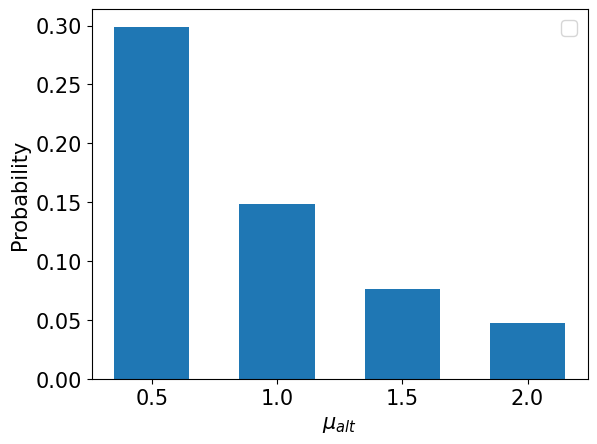

In [6]:
plt.rcParams.update({'font.size': 15})
plt.bar(x=MU_ALTS, height = np.mean(holm_stopping[:,:,1] < holm_stopping[:,:,0], axis = 0), width = 0.3, align = 'center', color = 'C0')

plt.xlabel(r'$\mu_{alt}$')
plt.ylabel('Probability')
plt.legend()
plt.show()

In [7]:
ratios = np.zeros(4)
for j in range(4):
  Ts_e = holm_stopping[:,j,1][holm_stopping[:,j,1] < holm_stopping[:,j,0]]
  Ts_p = holm_stopping[:,j,0][holm_stopping[:,j,1] < holm_stopping[:,j,0]]
  ratios[j] = np.mean(Ts_e / Ts_p)

### Figure 4 — Stopping-time ratio

/tmp/ipykernel_2781/3946773437.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


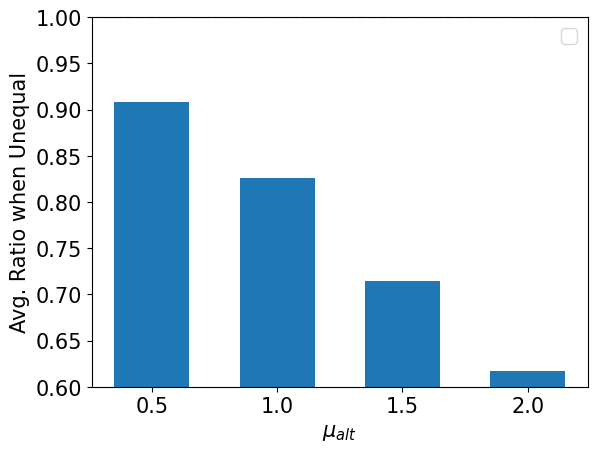

In [8]:
plt.rcParams.update({'font.size': 15})
plt.bar(x=MU_ALTS, height = ratios, width = 0.3, align = 'center', color = 'C0')

plt.ylim(0.6,1)
plt.xlabel(r'$\mu_{alt}$')
plt.ylabel('Avg. Ratio when Unequal')
plt.axhline(1, color = 'black', linestyle = 'dashed')
plt.legend()
plt.show()

### Figure 5 — Fixed-sample FWER

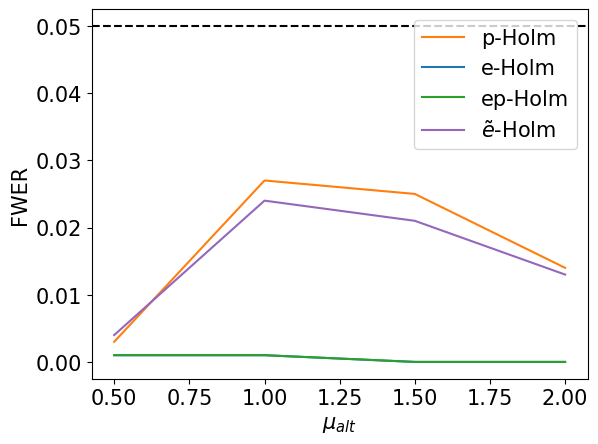

In [9]:
plt.rcParams.update({'font.size': 15})
colors = ['C1', 'C0', 'C2', 'C4']
methods = ['p-Holm','e-Holm','ep-Holm',r'$\tilde e$-Holm']
for i in range(4):
  plt.plot(MU_ALTS, holm_rates[:,i,0], label = methods[i], color = colors[i])

plt.xlabel(r'$\mu_{alt}$')
plt.ylabel('FWER')
plt.axhline(0.05, color = 'black', linestyle = 'dashed')
plt.legend()
plt.show()

### Figure 5 — Fixed-sample power

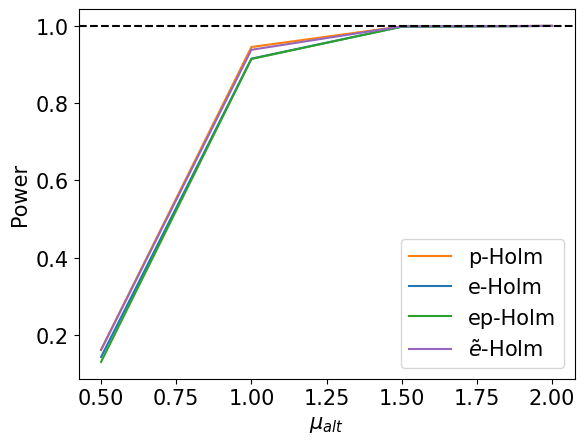

In [10]:
plt.rcParams.update({'font.size': 15})
colors = ['C1', 'C0', 'C2', 'C4']
methods = ['p-Holm','e-Holm','ep-Holm',r'$\tilde e$-Holm']
for i in range(4):
  plt.plot(MU_ALTS, holm_rates[:,i,1], label = methods[i], color = colors[i])

plt.xlabel(r'$\mu_{alt}$')
plt.ylabel('Power')
plt.axhline(1, color = 'black', linestyle = 'dashed')
plt.legend()
plt.show()

### Figure 6 — Relative power

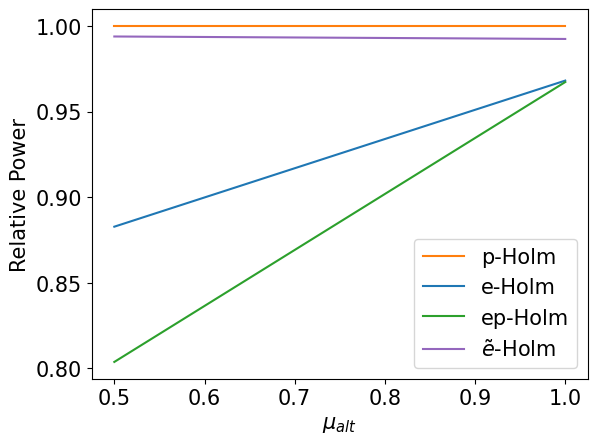

In [11]:
plt.rcParams.update({'font.size': 15})
colors = ['C1', 'C0', 'C2', 'C4']
methods = ['p-Holm', 'e-Holm', 'ep-Holm', r'$\tilde e$-Holm']
for i in range(4):
  plt.plot(MU_ALTS[:2], holm_rates[:2,i,1] / holm_rates[:2,0,1], label = methods[i], color = colors[i])
plt.xlabel(r'$\mu_{alt}$')
plt.ylabel('Relative Power')
plt.legend()
plt.show()

In [25]:
# Section 7.2 — Numerical summaries corresponding to the Figure 4 discussion.
p_times, e_times = holm_stopping[:,:,0], holm_stopping[:,:,1]
improvement = (e_times < p_times).mean(axis=0)
conditional_ratio = np.array([np.mean(e_times[:,j][e_times[:,j] != p_times[:,j]] /
                                        p_times[:,j][e_times[:,j] != p_times[:,j]])
                              for j in range(len(MU_ALTS))])
print('mu_alt:             ', MU_ALTS)
print('P(e-Holm faster):   ', np.round(improvement, 4))
print('E[Te/Tp | unequal]:', np.round(conditional_ratio, 4))
print('Minimum probability of improvement:', round(float(improvement.min()), 4))
print('Minimum conditional speed gain:', round(float((1-conditional_ratio).min()), 4))

mu_alt:              [0.5 1.  1.5 2. ]
P(e-Holm faster):    [0.299 0.148 0.076 0.047]
E[Te/Tp | unequal]: [0.908  0.826  0.7148 0.617 ]
Minimum probability of improvement: 0.047
Minimum conditional speed gain: 0.092


## Section 7.3 — Factorial e-DAG (200-step stopping times; 50-step fixed-sample power)

In [4]:
# The seven-contrast model; H123 is not included in plotted FWER or power.
vars = np.array([2, 2, 2, 4, 4, 4, 8])

beta_contrasts = np.array([
    # beta_1 = mu100 - mu000
    [-1,  0,  0,  0,  1,  0,  0,  0],

    # beta_2 = mu010 - mu000
    [-1,  0,  1,  0,  0,  0,  0,  0],

    # beta_3 = mu001 - mu000
    [-1,  1,  0,  0,  0,  0,  0,  0],

    # beta_12 = mu110 - mu100 - mu010 + mu000
    [ 1,  0, -1,  0, -1,  0,  1,  0],

    # beta_13 = mu101 - mu100 - mu001 + mu000
    [ 1, -1,  0,  0, -1,  1,  0,  0],

    # beta_23 = mu011 - mu010 - mu001 + mu000
    [ 1, -1, -1,  1,  0,  0,  0,  0],

    # beta_123 = mu111 - mu110 - mu101 - mu011 + mu100 + mu010 + mu001 - mu000
    [-1,  1,  1, -1,  1, -1, -1,  1],
], dtype=int)

def eval_factorial(data, mu_alt, vars = vars):
  contrasts = beta_contrasts @ data
  return np.exp(mu_alt * contrasts / vars - 0.5 * mu_alt ** 2 / vars)

def e_dag(evals, budget = 'primary', EB_divide = 7):
  d = EB_divide
  # ignore three-way interaction
  adj_evals = np.zeros(7)
  if budget == 'primary':
    for i in range(3):
      adj_evals[i] = evals[i] / 3
    adj_evals[3] = min((evals[0] + evals[1]) / 3, (evals[0] + evals[3] / 2) / 3, (evals[1] + evals[3] / 2) / 3, evals[3] / 3)
    adj_evals[4] = min((evals[0] + evals[2]) / 3, (evals[0] + evals[4] / 2) / 3, (evals[2] + evals[4] / 2) / 3, evals[4] / 3)
    adj_evals[5] = min((evals[1] + evals[2]) / 3, (evals[1] + evals[5] / 2) / 3, (evals[2] + evals[5] / 2) / 3, evals[5] / 3)
  else:
    for i in range(3):
      adj_evals[i] = evals[i] / d
    adj_evals[3] = min((evals[0] + evals[1] + evals[3]) / d, (evals[0] + 1.5 * evals[3]) / d,
     (evals[1] + 1.5 * evals[3]) / d, 2 * evals[3] / d)
    adj_evals[4] = min((evals[0] + evals[2] + evals[4]) / d, (evals[0] + 1.5 * evals[4]) / d,
     (evals[2] + 1.5 * evals[4]) / d, 2 * evals[4] / d)
    adj_evals[5] = min((evals[1] + evals[2] + evals[5]) / d, (evals[1] + 1.5 * evals[5]) / d,
     (evals[2] + 1.5 * evals[5]) / d, 2 * evals[5] / d)
  return adj_evals

def p_dag(pvals, budget = 'primary', EB_divide = 7):
  d = EB_divide
  adj_pvals = np.zeros(7)
  if budget == 'primary':
    for i in range(3):
      adj_pvals[i] = pvals[i] * 3
    adj_pvals[3] = max(min(pvals[0], pvals[1]) * 3, 3 * pvals[3], min(pvals[0], 2 * pvals[3]) * 3, min(pvals[1], 2 * pvals[3]) * 3)
    adj_pvals[4] = max(min(pvals[0], pvals[2]) * 3, 3 * pvals[4], min(pvals[0], 2 * pvals[4]) * 3, min(pvals[2], 2 * pvals[4]) * 3)
    adj_pvals[5] = max(min(pvals[1], pvals[2]) * 3, 3 * pvals[5], min(pvals[1], 2 * pvals[5]) * 3, min(pvals[2], 2 * pvals[5]) * 3)
  else:
    for i in range(3):
      adj_pvals[i] = pvals[i] * d
    adj_pvals[3] = max(min(pvals[0], pvals[1], pvals[3]) * d, d * pvals[3] / 2,
                       min(pvals[0], pvals[3] / 1.5) * d, min(pvals[1], pvals[3] / 1.5) * d)
    adj_pvals[4] = max(min(pvals[0], pvals[2], pvals[4]) * d, d * pvals[4] / 2,
                       min(pvals[0], pvals[4] / 1.5) * d, min(pvals[2], pvals[4] / 1.5) * d)
    adj_pvals[5] = max(min(pvals[1], pvals[2], pvals[5]) * d, d * pvals[5] / 2,
                       min(pvals[1], pvals[5] / 1.5) * d, min(pvals[2], pvals[5] / 1.5) * d)
  return adj_pvals

def run_processes_dag(mu_alt = 0.5, alpha = 0.05, max_steps = 2000, seed = 1, budget = 'primary'):
  data_means = np.array([0, 0.5, 0, 0.5, 0.5, 1+mu_alt, 0.5, 1+mu_alt])
  e_processes = np.ones(7)
  maxima = np.ones(7)
  mu_alts = np.zeros(7)
  mu_test = np.ones(7)/2

  null_indices = np.array([1, 3, 5])  # Ignore H123
  alt_indices = np.array([0, 2, 4])

  T_p = float('inf')
  T_e = float('inf')
  T_ep = float('inf')

  FWER_powers = np.zeros((3, 2))

  np.random.seed(seed)
  for t in range(max_steps):
    errors = np.random.normal(size = 8)
    data = data_means + errors
    if t > 10:
      mu_test[3:6] = mu_alts[3:6]
    e_processes = e_processes * eval_factorial(data, mu_test)
    maxima = np.maximum(maxima, e_processes)
    mu_alts = mu_alts * (t)/(t+1) + beta_contrasts @ data / (t+1)

    if T_p == float('inf'):
      best_p = np.min(p_dag(1/maxima, budget = budget)[3:6])
      if best_p <= alpha:
        T_p = t+1

    if T_ep == float('inf'):
      best_ep = np.min(p_dag(1/e_processes, budget = budget)[3:6])
      if best_ep <= alpha:
        T_ep = t+1

    if T_e == float('inf'):
      best_e = np.max(e_dag(e_processes, budget = budget)[3:6])
      if best_e >= 1/alpha:
        T_e = t+1


  Ts = np.array([T_p, T_e, T_ep])

  adj_pvals = p_dag(1/maxima, budget = budget)
  FWER_powers[0,0] = np.any(adj_pvals[null_indices] <= alpha)
  FWER_powers[0,1] = np.mean(adj_pvals[alt_indices] <= alpha)

  adj_evals = e_dag(e_processes, budget = budget)
  FWER_powers[1,0] = np.any(adj_evals[null_indices] >= 1/alpha)
  FWER_powers[1,1] = np.mean(adj_evals[alt_indices] >= 1/alpha)

  adj_epvals = p_dag(1/e_processes, budget = budget)
  FWER_powers[2,0] = np.any(adj_epvals[null_indices] <= alpha)
  FWER_powers[2,1] = np.mean(adj_epvals[alt_indices] <= alpha)

  return Ts, FWER_powers



MU_ALTS_DAG = np.array([0.5, 1, 1.5, 2])
N_REPLICATIONS_DAG = 1000
DAG_BUDGETS = ('primary', 'equal')
DAG_STOPPING_HORIZON = 200    # Figures 8--10
DAG_FIXED_HORIZON = 50       # Figure 11
DAG_STOPPING_CAP = 200       # plot censoring

# Run both budgets, separately for
# stopping times and fixed-sample power
def run_dag_both_budgets(n_replications=N_REPLICATIONS_DAG):
    results = {}
    for budget in DAG_BUDGETS:
        times = np.zeros((n_replications, len(MU_ALTS_DAG), 3))
        rates = np.zeros((n_replications, len(MU_ALTS_DAG), 3, 2))
        for i in tqdm(range(n_replications), desc=f'DAG {budget}'):
            for j, beta_13 in enumerate(MU_ALTS_DAG):
                stopping_times, _ = run_processes_dag(
                    mu_alt=beta_13, max_steps=DAG_STOPPING_HORIZON, seed=i, budget=budget)
                _, fixed_rates = run_processes_dag(
                    mu_alt=beta_13, max_steps=DAG_FIXED_HORIZON, seed=i, budget=budget)
                times[i,j] = stopping_times
                rates[i,j] = fixed_rates
        results[budget] = {'Ts_array': times, 'FWER_powers_array': rates}
    return results


In [5]:
dag_results = run_dag_both_budgets()

DAG primary:   0%|          | 0/1000 [00:00<?, ?it/s]

DAG equal:   0%|          | 0/1000 [00:00<?, ?it/s]

### Figure 8 — e-DAG versus p-DAG probabilities

**Primary budget**

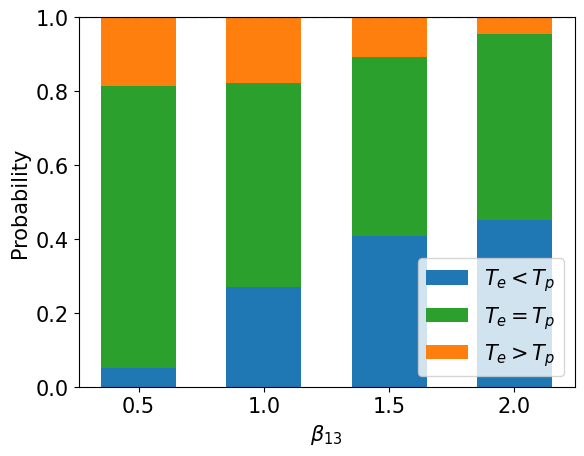

In [6]:
Ts_array = dag_results['primary']['Ts_array']
mu_1s = MU_ALTS_DAG
plt.rcParams.update({'font.size': 15})
p_less_e = np.mean(np.minimum(Ts_array[:,:,0], 200) < np.minimum(Ts_array[:,:,1], 200), axis = 0)
e_less_p = np.mean(np.minimum(Ts_array[:,:,1], 200) < np.minimum(Ts_array[:,:,0], 200), axis = 0)
p_equal_e = np.mean(np.minimum(Ts_array[:,:,1], 200) == np.minimum(Ts_array[:,:,0], 200), axis = 0)
plt.bar(x=mu_1s, height = e_less_p, width = 0.3, align = 'center', label = r'$T_e<T_p$', color = 'C0')
plt.bar(x=mu_1s, height = p_equal_e, bottom = e_less_p, width = 0.3, align = 'center', label = r'$T_e=T_p$', color = 'C2')
plt.bar(x=mu_1s, height = p_less_e, bottom = e_less_p + p_equal_e, width = 0.3, align = 'center', label = r'$T_e>T_p$', color = 'C1')

plt.ylim(0, 1)
plt.xlabel(r'$\beta_{13}$')
plt.ylabel('Probability')
plt.axhline(1, color = 'black', linestyle = 'dashed')
plt.legend()
plt.show()

**Equal budget**

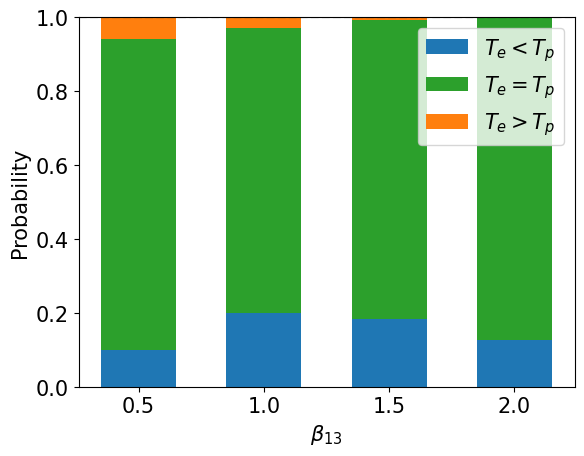

In [7]:
Ts_array = dag_results['equal']['Ts_array']
mu_1s = MU_ALTS_DAG
plt.rcParams.update({'font.size': 15})
p_less_e = np.mean(np.minimum(Ts_array[:,:,0], 200) < np.minimum(Ts_array[:,:,1], 200), axis = 0)
e_less_p = np.mean(np.minimum(Ts_array[:,:,1], 200) < np.minimum(Ts_array[:,:,0], 200), axis = 0)
p_equal_e = np.mean(np.minimum(Ts_array[:,:,1], 200) == np.minimum(Ts_array[:,:,0], 200), axis = 0)
plt.bar(x=mu_1s, height = e_less_p, width = 0.3, align = 'center', label = r'$T_e<T_p$', color = 'C0')
plt.bar(x=mu_1s, height = p_equal_e, bottom = e_less_p, width = 0.3, align = 'center', label = r'$T_e=T_p$', color = 'C2')
plt.bar(x=mu_1s, height = p_less_e, bottom = e_less_p + p_equal_e, width = 0.3, align = 'center', label = r'$T_e>T_p$', color = 'C1')

plt.ylim(0, 1)
plt.xlabel(r'$\beta_{13}$')
plt.ylabel('Probability')
plt.axhline(1, color = 'black', linestyle = 'dashed')
plt.legend()
plt.show()

### Figure 9 — e-DAG versus ep-DAG probabilities

**Primary budget**

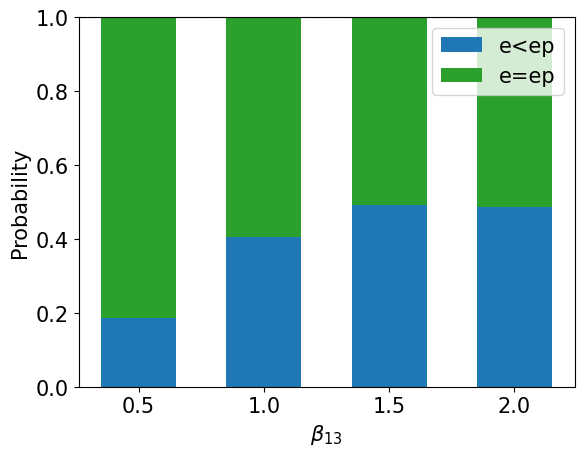

In [8]:
Ts_array = dag_results['primary']['Ts_array']
mu_1s = MU_ALTS_DAG
plt.rcParams.update({'font.size': 15})
e_less_ep = np.mean(np.minimum(Ts_array[:,:,2], 200) > np.minimum(Ts_array[:,:,1], 200), axis = 0)
plt.bar(x=mu_1s, height = e_less_ep, width = 0.3, align = 'center', label = 'e<ep', color = 'C0')
plt.bar(x=mu_1s, height = 1 - e_less_ep, bottom = e_less_ep, width = 0.3, align = 'center', label = 'e=ep', color = 'C2')
plt.ylim(0, 1)
plt.xlabel(r'$\beta_{13}$')
plt.ylabel('Probability')
plt.axhline(1, color = 'black', linestyle = 'dashed')
plt.legend()
plt.show()

**Equal budget**

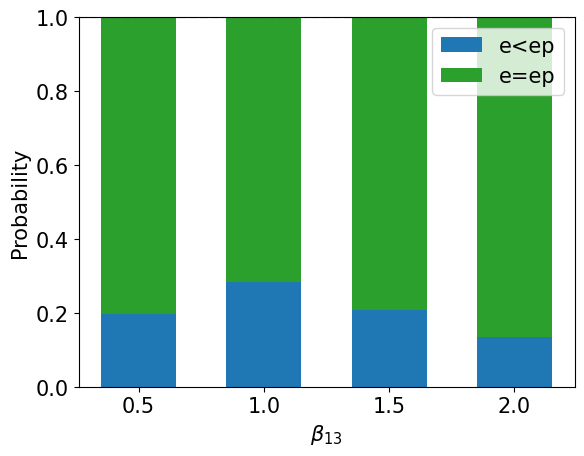

In [9]:
Ts_array = dag_results['equal']['Ts_array']
mu_1s = MU_ALTS_DAG
plt.rcParams.update({'font.size': 15})
e_less_ep = np.mean(np.minimum(Ts_array[:,:,2], 200) > np.minimum(Ts_array[:,:,1], 200), axis = 0)
plt.bar(x=mu_1s, height = e_less_ep, width = 0.3, align = 'center', label = 'e<ep', color = 'C0')
plt.bar(x=mu_1s, height = 1 - e_less_ep, bottom = e_less_ep, width = 0.3, align = 'center', label = 'e=ep', color = 'C2')
plt.ylim(0, 1)
plt.xlabel(r'$\beta_{13}$')
plt.ylabel('Probability')
plt.axhline(1, color = 'black', linestyle = 'dashed')
plt.legend()
plt.show()

### Figure 10 — Conditional stopping-time ratios

**Primary budget**

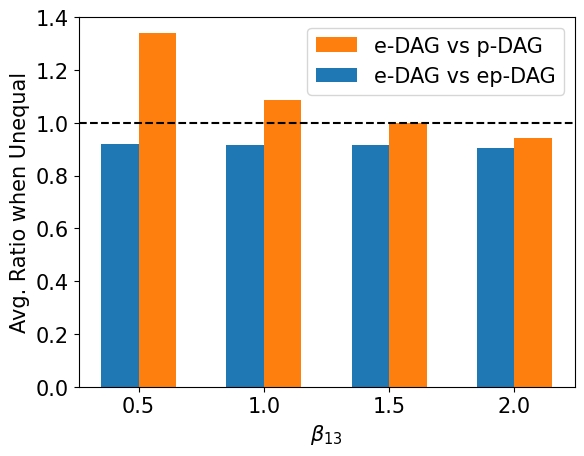

In [10]:
Ts_array = dag_results['primary']['Ts_array']
mu_1s = MU_ALTS_DAG
ratios_ep = np.zeros(4)
for j in range(4):
  Ts_e = np.minimum(Ts_array[:,j,1][Ts_array[:,j,1] < Ts_array[:,j,2]], 200)
  Ts_ep = np.minimum(Ts_array[:,j,2][Ts_array[:,j,1] < Ts_array[:,j,2]], 200)
  ratios_ep[j] = np.mean(Ts_e / Ts_ep)

ratios_p = np.zeros(4)
for j in range(4):
  Ts_e = np.minimum(Ts_array[:,j,1][Ts_array[:,j,1] != Ts_array[:,j,0]], 200)
  Ts_p = np.minimum(Ts_array[:,j,0][Ts_array[:,j,1] != Ts_array[:,j,0]], 200)
  ratios_p[j] = np.mean(Ts_e / Ts_p)
plt.rcParams.update({'font.size': 15})
plt.bar(x=mu_1s, height = ratios_p, width = 0.15, align = 'edge', label = 'e-DAG vs p-DAG', color = 'C1')
plt.bar(x=mu_1s, height = ratios_ep, width = -0.15, align = 'edge', label = 'e-DAG vs ep-DAG', color = 'C0')

plt.ylim(0,1.4)
plt.xlabel(r'$\beta_{13}$')
plt.ylabel('Avg. Ratio when Unequal')
plt.axhline(1, color = 'black', linestyle = 'dashed')
plt.legend()
plt.show()

**Equal budget**

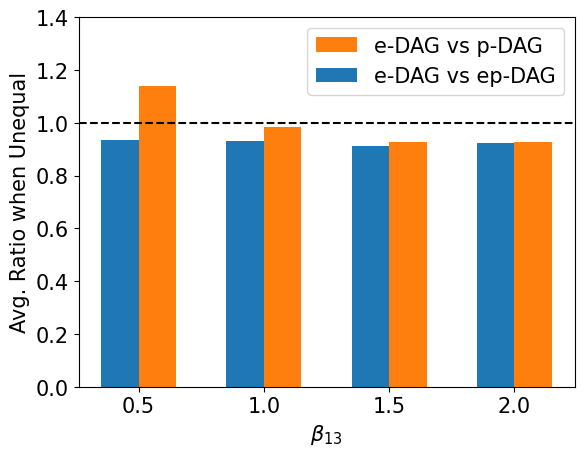

In [11]:
Ts_array = dag_results['equal']['Ts_array']
mu_1s = MU_ALTS_DAG
ratios_ep = np.zeros(4)
for j in range(4):
  Ts_e = np.minimum(Ts_array[:,j,1][Ts_array[:,j,1] < Ts_array[:,j,2]], 200)
  Ts_ep = np.minimum(Ts_array[:,j,2][Ts_array[:,j,1] < Ts_array[:,j,2]], 200)
  ratios_ep[j] = np.mean(Ts_e / Ts_ep)

ratios_p = np.zeros(4)
for j in range(4):
  Ts_e = np.minimum(Ts_array[:,j,1][Ts_array[:,j,1] != Ts_array[:,j,0]], 200)
  Ts_p = np.minimum(Ts_array[:,j,0][Ts_array[:,j,1] != Ts_array[:,j,0]], 200)
  ratios_p[j] = np.mean(Ts_e / Ts_p)
plt.rcParams.update({'font.size': 15})
plt.bar(x=mu_1s, height = ratios_p, width = 0.15, align = 'edge', label = 'e-DAG vs p-DAG', color = 'C1')
plt.bar(x=mu_1s, height = ratios_ep, width = -0.15, align = 'edge', label = 'e-DAG vs ep-DAG', color = 'C0')

plt.ylim(0,1.4)
plt.xlabel(r'$\beta_{13}$')
plt.ylabel('Avg. Ratio when Unequal')
plt.axhline(1, color = 'black', linestyle = 'dashed')
plt.legend()
plt.show()

### Figure 11 — Fixed-horizon power

**Primary budget**

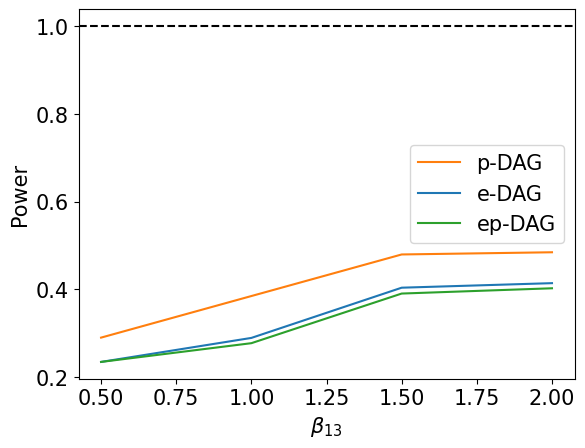

In [12]:
FWER_powers_array = dag_results['primary']['FWER_powers_array']
mu_1s = MU_ALTS_DAG
plt.rcParams.update({'font.size': 15})
colors = ['C1', 'C0', 'C2']
methods = ['p-DAG','e-DAG','ep-DAG']
for i in range(3):
  plt.plot(mu_1s, np.mean(FWER_powers_array[:,:,i,1], axis = 0), label = methods[i], color = colors[i])

plt.xlabel(r'$\beta_{13}$')
plt.ylabel('Power')
plt.axhline(1, color = 'black', linestyle = 'dashed')
plt.legend()
plt.show()

**Equal budget**

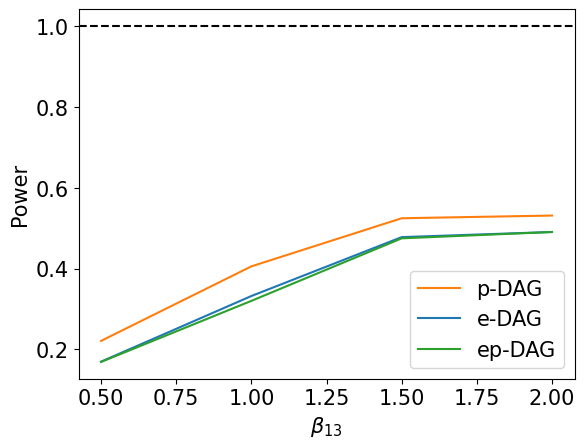

In [13]:
FWER_powers_array = dag_results['equal']['FWER_powers_array']
mu_1s = MU_ALTS_DAG
plt.rcParams.update({'font.size': 15})
colors = ['C1', 'C0', 'C2']
methods = ['p-DAG','e-DAG','ep-DAG']
for i in range(3):
  plt.plot(mu_1s, np.mean(FWER_powers_array[:,:,i,1], axis = 0), label = methods[i], color = colors[i])

plt.xlabel(r'$\beta_{13}$')
plt.ylabel('Power')
plt.axhline(1, color = 'black', linestyle = 'dashed')
plt.legend()
plt.show()

### Section 7.3 — Fixed-horizon FWER (reported in text)

**Primary budget**

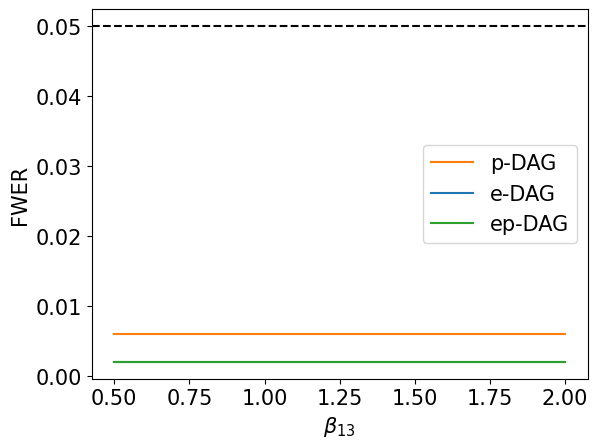

In [14]:
FWER_powers_array = dag_results['primary']['FWER_powers_array']
mu_1s = MU_ALTS_DAG
plt.rcParams.update({'font.size': 15})
colors = ['C1', 'C0', 'C2']
methods = ['p-DAG','e-DAG','ep-DAG']
for i in range(3):
  plt.plot(mu_1s, np.mean(FWER_powers_array[:,:,i,0], axis = 0), label = methods[i], color = colors[i])

plt.xlabel(r'$\beta_{13}$')
plt.ylabel('FWER')
plt.axhline(0.05, color = 'black', linestyle = 'dashed')
plt.legend()
plt.show()

**Equal budget**

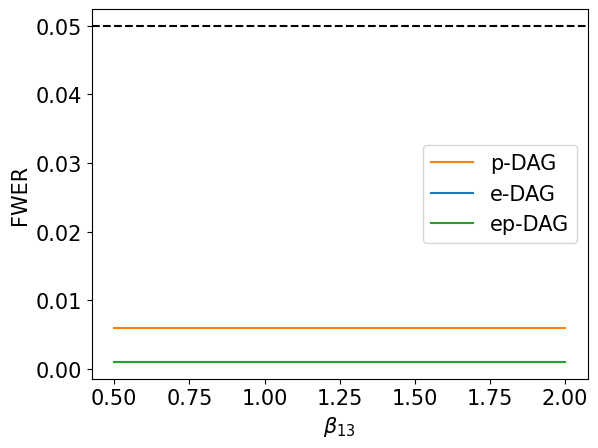

In [15]:
FWER_powers_array = dag_results['equal']['FWER_powers_array']
mu_1s = MU_ALTS_DAG
plt.rcParams.update({'font.size': 15})
colors = ['C1', 'C0', 'C2']
methods = ['p-DAG','e-DAG','ep-DAG']
for i in range(3):
  plt.plot(mu_1s, np.mean(FWER_powers_array[:,:,i,0], axis = 0), label = methods[i], color = colors[i])

plt.xlabel(r'$\beta_{13}$')
plt.ylabel('FWER')
plt.axhline(0.05, color = 'black', linestyle = 'dashed')
plt.legend()
plt.show()

In [16]:
# Section 7.3 — Numeric values reported in the prose (Figures 8–11).
# Stopping-time comparisons use 200 steps; FWER/power uses 50 steps.
for budget in DAG_BUDGETS:
    times = dag_results[budget]['Ts_array']
    rates = dag_results[budget]['FWER_powers_array'].mean(axis=0)
    e, p, ep = times[:,:,1], times[:,:,0], times[:,:,2]
    cutoff = DAG_STOPPING_CAP
    ratio_p = np.array([np.mean(np.minimum(e[:,j][e[:,j] != p[:,j]], cutoff) /
                                np.minimum(p[:,j][e[:,j] != p[:,j]], cutoff))
                        if np.any(e[:,j] != p[:,j]) else np.nan for j in range(len(MU_ALTS_DAG))])
    print(f'\n{budget.upper()} budget')
    print('P(e faster than p): ', np.round((e<p).mean(axis=0),3))
    print('P(p faster than e): ', np.round((p<e).mean(axis=0),3))
    print('E[Te/Tp | unequal]:', np.round(ratio_p,3))
    print('FWER of p/e/ep by beta_13 (H2,H12,H23 only):')
    print(np.round(rates[:,:,0].T,3))
    print('Mean FWER across beta_13:', np.round(rates[:,:,0].mean(axis=0),3))


PRIMARY budget
P(e faster than p):  [0.052 0.271 0.407 0.45 ]
P(p faster than e):  [0.187 0.178 0.107 0.047]
E[Te/Tp | unequal]: [1.339 1.087 0.997 0.942]
FWER of p/e/ep by beta_13 (H2,H12,H23 only):
[[0.006 0.006 0.006 0.006]
 [0.002 0.002 0.002 0.002]
 [0.002 0.002 0.002 0.002]]
Mean FWER across beta_13: [0.006 0.002 0.002]

EQUAL budget
P(e faster than p):  [0.099 0.199 0.182 0.127]
P(p faster than e):  [0.058 0.029 0.008 0.001]
E[Te/Tp | unequal]: [1.138 0.984 0.928 0.928]
FWER of p/e/ep by beta_13 (H2,H12,H23 only):
[[0.006 0.006 0.006 0.006]
 [0.001 0.001 0.001 0.001]
 [0.001 0.001 0.001 0.001]]
Mean FWER across beta_13: [0.006 0.001 0.001]
